# Task 21 — Port congestion from AIS: how long will this ship wait at anchor?

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [LA/LB Maritime Trajectory & AIS Dataset 2023–2025](https://www.kaggle.com/datasets/nguyenductuandat/lalb-ais-port-congestion-62023-122025) (21.7 M AIS pings off Los Angeles / Long Beach, from NOAA Marine Cadastre)
**Task family:** geospatial event extraction, arrival-time regression with a quantile promise, a versioned label, drift · **Companion task:** `02_card_fraud_tabular.ipynb` (forward evaluation, operating point from business constants)

---

## The task card

> **Board question.** *In 2023–2025 one ship in five that berthed at Los Angeles / Long Beach waited at anchor first, for a median 35 hours; tankers waited on 58 % of their calls. When a ship enters San Pedro Bay, can we tell it how long it will wait, better than today's silent "come straight in", and see a queue building before the anchorages fill?*

**Business context.** The question was born in the 2021–22 backlog, when container ships queued for weeks off San Pedro Bay; this data starts in June 2023, after it cleared. A ship that waits longer than planned burns charter time and fuel at anchor; one told to wait longer than needed leaves a berth idle. The service is Session 01's *online prediction* pattern, `POST /eta` per arriving ship, inside a legacy estate of AIS receivers, vessel traffic services, the port community system and terminal operating systems, with a *human-in-the-loop* harbour master reading a queue briefing. The same pattern applies at Malta Freeport, a transshipment hub.

**What you will build from this notebook (see *Student tasks* at the end):**

1. a **visit and label pipeline** from pings to arrivals, anchorage stops and berthings, its geofence versioned like a model;
2. the given **arrival-time wait model**, packaged and reproducible, evaluated forward by half-year, with the traps guarded by tests;
3. an **operating point**: which quantile of the wait to promise, priced in an ADR;
4. the **operational wrapper**: package, CI gate on a frozen 2025 H2, registry, model card, monitoring;
5. a **port knowledge base** with its ablation, and the facts for a harbour-master briefing.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Scoring at arrival inside a port community system; AIS governance |
| 2 · MLOps | A geofence-defined, versioned label; half-year forward validation; a quantile promise; drift and a retraining gate |
| 3 · Semantic layer | Port ontology, SHACL, vessel–terminal graph, terminal-context ablation |
| 4 · LLM/RAG | A harbour-master briefing grounded in computed queue facts |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The pings are **real** AIS, re-processed by one person "over approximately one month" (the uploader's words) and little used (two public notebooks, 283 downloads by October 2026). Its visits and label do not survive inspection, so we rebuild both. "Waiting for a berth" has no ground truth: our label is a definition, and Trap 1 measures how much that matters.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, what the published processing hides, the learned geofence | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | Visits and the versioned label, the port knowledge base, features as of arrival, the median model, the promise quantile, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The model after deployment, the CI gate on 2025 H2, the briefing facts, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the concept drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_pings` (Section 1); the learned geofence (Section 2); `make_visits`, the knowledge base and `build_features` with `covering`, `in_window` and `trailing_mean` (Section 3); `fit` and `scores` (Section 4); `promise_cost` (Section 5); `label_stats` (Section 6); `psi` and `briefing_facts` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 12,910 visits, 8,321 berthed (geofence v2); 3,110 training arrivals, 1,599 validation, 1,554 test (2025 H1) and 1,520 in the frozen 2025 H2 holdout; on 2025 H1 the median model with terminal context scores MAE 10.51 h against 11.16 h for telling everyone zero, and AUPRC 0.519 for waits over 24 h; the q = 0.5 promise costs $19,922 per arrival against $22,315, saving $3,719,643 over the half-year.
- **Runtime:** about 1–2 minutes on a laptop (76 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import duckdb
import lightgbm as lgb
import networkx as nx
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace
from rdflib.namespace import RDF, RDFS, XSD
from sklearn.cluster import KMeans
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                   # one thread: faster on a shared laptop, and deterministic
KAGGLE_HANDLE = "nguyenductuandat/lalb-ais-port-congestion-62023-122025"
SOURCE_FILE = "ais_2023_2025_clean.parquet"  # the merged file; the five half-year files are not needed
EPOCH0 = pd.Timestamp("2023-01-01", tz="UTC")             # pings are stored as int32 seconds after this instant
WARMUP_END = pd.Timestamp("2023-06-08", tz="UTC")         # the first week only feeds the as-of features
TRAIN_END = pd.Timestamp("2024-07-01", tz="UTC")          # train: Jun 2023 – Jun 2024 (files 2023H2, 2024H1)
VALID_END = pd.Timestamp("2025-01-01", tz="UTC")          # validation: 2024 H2 (operating point)
TEST_END = pd.Timestamp("2025-07-01", tz="UTC")           # test: 2025 H1 · frozen holdout: 2025 H2 (CI gate, read once)
# ---- the label definition, versioned (Section 3, Trap 1) ----
GEOFENCE_VERSION = "v2"     # v1: the two San Pedro Bay anchorage groups · v2: plus the south-east overflow anchorage
CELL_DEG = 0.002            # geofence grid, about 200 m
MIN_CELL_PINGS = 50         # stationary training pings before a cell is classified
SLOW_KN = 0.5               # below this speed a ship is stationary
MIN_STOP_MIN = 30           # a shorter stop is neither anchoring nor berthing
VISIT_GAP_H = 12            # an AIS silence this long starts a new visit (Trap 2)
MAX_WAIT_H = 336            # "waits" over 14 days are lay-ups or repairs, not a queue: excluded and counted
LONG_WAIT_H = 24            # the waits the harbour master is asked about
N_TERMINALS = 10            # berth zones clustered from where ships tie up (Section 3)
# ---- business constants (assumptions — vary them in task C3) ----
ANCHOR_COST_USD_PER_H = 2_000      # a ship waits longer than it was told: charter time, fuel and emissions at anchor
IDLE_BERTH_COST_USD_PER_H = 1_500  # a ship was told to wait longer than needed: berth, gang and pilots stand idle
GATE_MAE_VS_ZERO = 0.97            # CI gate: holdout MAE ≤ 97 % of the "tell everyone zero" rule = validation ratio + 0.05 (placeholder — task C4)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "lalb_ais", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
sec = lambda ts: int((ts - EPOCH0).total_seconds())            # timestamp -> stored seconds
when = lambda s: EPOCH0 + pd.to_timedelta(np.asarray(s, dtype="float64"), unit="s")
print(f"pandas {pd.__version__} · duckdb {duckdb.__version__} · lightgbm {lgb.__version__} · numpy {np.__version__} · "
      f"networkx {nx.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · duckdb 2.0.0 · lightgbm 4.7.0 · numpy 2.5.4 · networkx 3.7 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_pings`.*

| Field | Value |
|---|---|
| **Source** | Kaggle `nguyenductuandat/lalb-ais-port-congestion-62023-122025` (Kelvin Nguyen, version 3, May 2026); pings from NOAA Marine Cadastre AIS, weather from Open-Meteo |
| **Licence** | CC BY 4.0: attribute the uploader and NOAA Marine Cadastre |
| **Provenance** | Real AIS cut to a box off San Pedro Bay, cleaned, imputed and feature-engineered by the uploader |
| **Size** | 21,678,617 pings of 3,376 vessels, 1 Jun 2023 – 31 Dec 2025 (UTC), 53 columns, a median 180 s apart |
| **Files** | `ais_2023_2025_clean.parquet` (575 MB, merged; the only file used). Five half-year files (707 MB) are not needed |
| **Schema** | identifiers (`mmsi`, `vessel_name`, `imo`, `call_sign`, `visit_id`), AIS kinematics and `status`, vessel type and size, engineered columns, `delay_minutes`, weather |
| **Label** | None fit for purpose (quirks 1–2); we build *hours at anchor before the first berthing* (Section 3) |
| **Window used here** | All of it: train Jun 2023 – Jun 2024, validate 2024 H2, test 2025 H1, frozen holdout 2025 H2. DuckDB builds a 147 MB time-sorted cache out of core; 369 MB of pings in memory, under 2 GB at peak. On a small laptop, read the cache with a `filters=` time window and shift the split dates |
| **PII** | MMSI, IMO, call sign and name identify a ship and, through registers, its operator. Names, IMO and call signs are never read; MMSI becomes a salted-hash pseudonym on load |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **`visit_id` restarts in every half-year file**, so the merged file joins unrelated calls: 42 % of its 6,562 (`mmsi`, `visit_id`) pairs span two or more half-years. The description's "6,562 port visits" is this artefact; re-segmenting gives 12,910 visits, 8,321 of which berth (Trap 2).
2. ⚠ **`delay_minutes` is not a waiting time.** It runs from entering the zone to mooring: a median 3.3 h for calls that never touched the waiting area (Trap 1).
3. ⚠ **The navigation status is typed by the crew:** 29.7 % of "under way" pings are stationary.
4. ⚠ **Columns that describe the visit's future.** Aggregated per visit, `time_in_zone_hours` and the waiting flag read later pings (Trap 3); so does the backward-filled draft imputation.
5. **`is_in_waiting_area` is crew status plus a 3–20 km ring**, blind to the south-east overflow anchorage.
6. **Pings every three minutes, not every minute**; 7,237 silences exceed three days.
7. **Only cargo ships (AIS types 70–79) and tankers (80–89)**; AIS type cannot tell container ships from bulk carriers.
8. **The box is 33.5–33.9° N, 118.0–118.5° W**, not "UTM Zone 11"; waiting further offshore is invisible.
9. **Times are UTC**; hour and weekday are converted to Los Angeles time.

In [2]:
PING_CACHE, VISIT_CACHE = PROCESSED / "21_pings.parquet", PROCESSED / "21_published_visits.parquet"

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_pings() -> None:
    """Cache a compact, time-sorted copy of the pings and a per-published-visit summary (DuckDB, out of core)."""
    if PING_CACHE.exists() and VISIT_CACHE.exists():
        return
    t0 = time.time()
    src = get_raw(SOURCE_FILE).as_posix()
    e0 = int(EPOCH0.timestamp())
    salt = os.environ.get("AIS_PSEUDONYM_SALT", "teaching-only-salt")      # production: a secret store, never Git
    con = duckdb.connect()
    con.execute(f"SET memory_limit='1GB'; SET threads=1; SET TimeZone='UTC'; SET preserve_insertion_order=false; "
                f"SET temp_directory='{(PROCESSED / '21_duckdb_tmp').as_posix()}'")
    # ---- governance on load: MMSI becomes a salted-hash pseudonym; vessel_name, imo and call_sign are never read ----
    con.execute(f"""CREATE TEMP TABLE ids AS SELECT mmsi, dense_rank() OVER (ORDER BY md5('{salt}' || mmsi::VARCHAR))::INTEGER AS vessel
                    FROM (SELECT DISTINCT mmsi FROM read_parquet('{src}'))""")
    con.execute(f"""COPY (
        SELECT i.vessel, (epoch(p.base_date_time) - {e0})::INTEGER AS t, p.latitude::FLOAT AS lat, p.longitude::FLOAT AS lon,
               p.sog::FLOAT AS sog, coalesce(p.status, -1)::TINYINT AS status, p.visit_id::SMALLINT AS pub_visit,
               p.vessel_type::TINYINT AS vessel_type, p.length::SMALLINT AS length, p.width::SMALLINT AS width, p.draft::FLOAT AS draft
        FROM read_parquet('{src}') p JOIN ids i USING (mmsi) ORDER BY i.vessel, t
    ) TO '{PING_CACHE.as_posix()}' (FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 1000000)""")
    # the published visits per half-year file, with the published label and engineered columns aggregated over each one
    con.execute(f"""COPY (
        SELECT i.vessel, p.visit_id::SMALLINT AS pub_visit,
               (year(p.base_date_time) * 10 + CASE WHEN month(p.base_date_time) <= 6 AND year(p.base_date_time) > 2023 THEN 1 ELSE 2 END)::SMALLINT AS half,
               count(*) AS pings, (min(epoch(p.base_date_time)) - {e0})::INTEGER AS t_first, (max(epoch(p.base_date_time)) - {e0})::INTEGER AS t_last,
               max(p.delay_minutes) / 60 AS pub_delay_h, avg(p.is_in_waiting_area::INT) AS pub_waiting_share,
               max(p.time_in_zone_hours) AS pub_time_in_zone_max, avg(p.ship_density) AS pub_density_mean
        FROM read_parquet('{src}') p JOIN ids i USING (mmsi) GROUP BY ALL
    ) TO '{VISIT_CACHE.as_posix()}' (FORMAT parquet)""")
    con.close()
    print(f"cached in {time.time() - t0:.0f}s")

load_pings()
tb = pq.read_table(PING_CACHE, columns=["vessel", "t", "lat", "lon", "sog", "status"])
vessel, t, sog, status = (tb.column(c).to_numpy() for c in ["vessel", "t", "sog", "status"])
NLAT, NLON = round(0.4 / CELL_DEG) + 1, round(0.5 / CELL_DEG) + 1      # the box is 33.5–33.9° N, 118.5–118.0° W
cell = (np.clip(((tb.column("lat").to_numpy() - 33.5) / CELL_DEG).astype(np.int32), 0, NLAT - 1) * NLON
        + np.clip(((tb.column("lon").to_numpy() + 118.5) / CELL_DEG).astype(np.int32), 0, NLON - 1))
lat_range = (pc.min(tb.column("lat")).as_py(), pc.max(tb.column("lat")).as_py())
lon_range = (pc.min(tb.column("lon")).as_py(), pc.max(tb.column("lon")).as_py())
del tb; pa.default_memory_pool().release_unused()
pub = pd.read_parquet(VISIT_CACHE)                         # one row per (vessel, visit_id, half-year file)
N = len(t)
gap = np.diff(t)[vessel[1:] == vessel[:-1]]
src_meta = pq.ParquetFile(get_raw(SOURCE_FILE)).metadata
print(f"source: {src_meta.num_columns} columns, {get_raw(SOURCE_FILE).stat().st_size / 1e6:.0f} MB · {N:,} pings · {vessel.max():,} vessels · {when(t.min()).strftime('%d %b %Y')} – {when(t.max()).strftime('%d %b %Y')} (UTC) · "
      f"box {lat_range[0]:.2f}–{lat_range[1]:.2f}° N, {-lon_range[1]:.2f}–{-lon_range[0]:.2f}° W · median ping interval {np.median(gap):.0f} s · "
      f"{pub.groupby(['vessel', 'pub_visit']).ngroups:,} published (vessel, visit_id) pairs · cache {PING_CACHE.stat().st_size / 1e6:.0f} MB on disk, "
      f"{(vessel.nbytes + t.nbytes + sog.nbytes + status.nbytes + cell.nbytes) / 1e6:.0f} MB in memory")
del gap

source: 53 columns, 575 MB · 21,678,617 pings · 3,376 vessels · 01 Jun 2023 – 31 Dec 2025 (UTC) · box 33.50–33.90° N, 118.00–118.50° W · median ping interval 180 s · 6,562 published (vessel, visit_id) pairs · cache 147 MB on disk, 369 MB in memory


## 2 · First look: what the published processing hides

*Part A · Explore · read; package the learned geofence, built on training months only, as a versioned pipeline step.*

Two public notebooks means nobody has checked this upload for you. Before trusting a column, ask four questions: what is a visit, what is the label, who typed the status, and what does the waiting flag test?

In [3]:
# 1 · the published visit_id: does it restart in every half-year file?
FILES = ["2023H2 (Jun–Dec 2023)", "2024H1", "2024H2", "2025H1", "2025H2"]
bounds = [sec(pd.Timestamp(d, tz="UTC")) for d in ["2024-01-01", "2024-07-01", "2025-01-01", "2025-07-01"]]
hcode = np.searchsorted(bounds, t, side="right").astype(np.int8)
pub_visit = pq.read_table(PING_CACHE, columns=["pub_visit"]).column(0).to_numpy()
audit = pd.DataFrame({k: {"pings": int((hcode == k).sum()), "vessels": len(np.unique(vessel[hcode == k])),
                          "highest visit_id": int(pub_visit[hcode == k].max())} for k in range(5)}).T
audit.index = FILES
display(audit)
del hcode, pub_visit
merged = pub.groupby(["vessel", "pub_visit"]).agg(halves=("half", "nunique"), t_first=("t_first", "min"), t_last=("t_last", "max"))
span_d = (merged.t_last - merged.t_first) / 86400
print(f"published (vessel, visit_id) pairs spanning more than one half-year file: {(merged.halves > 1).mean():.0%} · "
      f"median span {span_d.median():.1f} days · mean {span_d.mean():.0f} days · longest {span_d.max():.0f} days")
# 2 · the published label on calls that never entered the published waiting area
never_waited = pub[(pub.pub_waiting_share == 0) & pub.pub_delay_h.notna()]
print(f"published delay_minutes where the ship never entered the waiting area: median {never_waited.pub_delay_h.median():.1f} h "
      f"(n = {len(never_waited):,} visit-files); missing on {pub.pub_delay_h.isna().mean():.0%} of them")
# 3 · the navigation status is typed by the crew: what was reported, against how fast the ship was moving
s_code = np.select([status == 0, status == 1, status == 5], [0, 1, 2], 3)
v_code = np.digitize(np.nan_to_num(sog, nan=-1.0), [0.5, 3.0])        # 0: < 0.5 kn (or unknown), 1: 0.5–3 kn, 2: > 3 kn
xt = np.bincount(s_code * 3 + v_code, minlength=12).reshape(4, 3)
st = pd.DataFrame(xt / xt.sum(axis=1, keepdims=True), index=["0 under way", "1 at anchor", "5 moored", "other / missing"],
                  columns=["< 0.5 kn", "0.5–3 kn", "> 3 kn"]).assign(pings=xt.sum(axis=1))
display(st.style.format({c: "{:.1%}" for c in st.columns[:3]} | {"pings": "{:,}"}))
del s_code, v_code
# 4 · what the published `is_in_waiting_area` flag actually requires
wa = duckdb.sql(f"""SELECT avg((status = 1)::INT) AS crew_anchor, avg((sog < 0.5)::INT) AS slow, min(distance_to_port) AS min_km, max(distance_to_port) AS max_km
                    FROM read_parquet('{get_raw(SOURCE_FILE).as_posix()}') WHERE is_in_waiting_area""").df().iloc[0]
out = duckdb.sql(f"""SELECT count(*) AS n, count(*) FILTER (WHERE latitude < 33.64 AND longitude > -118.10) AS south_east
                     FROM read_parquet('{get_raw(SOURCE_FILE).as_posix()}') WHERE status = 1 AND sog < 0.5 AND distance_to_port >= 20""").df().iloc[0]
print(f"published waiting-area pings: {wa.crew_anchor:.1%} have crew status 1 (at anchor), {wa.slow:.1%} are below 0.5 kn, all lie "
      f"{wa.min_km:.1f}–{wa.max_km:.1f} km from the port centre · stationary 'at anchor' pings beyond 20 km, never flagged: {out.n:,} "
      f"({out.south_east:,} of them south-east of 33.64° N, 118.10° W)")

,pings,vessels,highest visit_id
2023H2 (Jun–Dec 2023),5031462,1184,40
2024H1,4394343,1125,26
2024H2,4444408,1210,50
2025H1,4246223,1167,35
2025H2,3562181,1093,39


published (vessel, visit_id) pairs spanning more than one half-year file: 42% · median span 6.8 days · mean 185 days · longest 918 days
published delay_minutes where the ship never entered the waiting area: median 3.3 h (n = 6,013 visit-files); missing on 29% of them


,< 0.5 kn,0.5–3 kn,> 3 kn,pings
0 under way,29.7%,9.0%,61.3%,"4,317,157"
1 at anchor,98.0%,1.9%,0.1%,"6,012,909"
5 moored,99.1%,0.5%,0.4%,"10,975,690"
other / missing,78.1%,3.7%,18.2%,"372,861"


published waiting-area pings: 100.0% have crew status 1 (at anchor), 100.0% are below 0.5 kn, all lie 3.0–20.0 km from the port centre · stationary 'at anchor' pings beyond 20 km, never flagged: 689,253 (585,981 of them south-east of 33.64° N, 118.10° W)


The highest `visit_id` per file is 26–50 and the merged file reuses the numbers, so a vessel's "visit 1" of 2023 and of 2024 become one visit. The published label is mostly transit: a median 3.3 h for ships that never entered the waiting area. The crew's status is right on average (98.0 % of "at anchor" pings are stationary), yet 29.7 % of "under way" pings are stationary too. And the waiting flag skips 689,253 stationary "at anchor" pings beyond 20 km, 585,981 of them in the south-east.

So we let the fleet draw the map: every ~200 m cell takes the majority status of stationary ships there **in the training months** (at least 50 pings). One crew's stale status is outvoted, and later months never shape the geofence that labels them.

162 berth cells, 765 anchorage cells · pings by learned zone: elsewhere 18.7%, berth (harbour) 52.3%, near anchorage 11.9%, outer anchorage 13.6%, south-east overflow 3.1%, Santa Monica Bay 0.6%


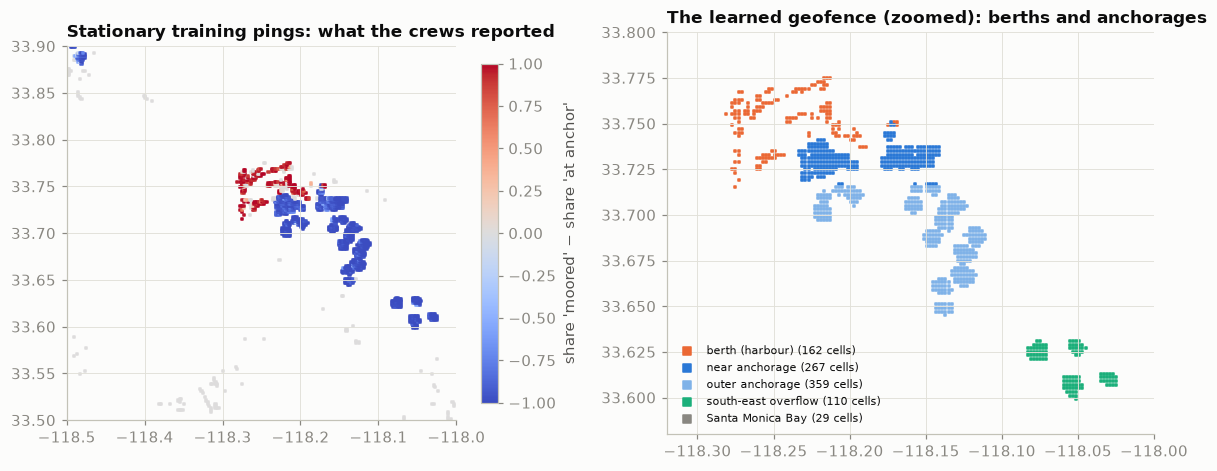

In [4]:
# Let the fleet draw the map: classify every ~200 m cell by what stationary ships there reported in the TRAINING months
slow_tr = (sog < SLOW_KN) & (t < sec(TRAIN_END))
n_slow = np.bincount(cell[slow_tr], minlength=NLAT * NLON)
n_anchor = np.bincount(cell[slow_tr & (status == 1)], minlength=NLAT * NLON)
n_moored = np.bincount(cell[slow_tr & (status == 5)], minlength=NLAT * NLON)
del slow_tr
clat = 33.5 + (np.arange(NLAT * NLON) // NLON + 0.5) * CELL_DEG
clon = -118.5 + (np.arange(NLAT * NLON) % NLON + 0.5) * CELL_DEG
ok = n_slow >= MIN_CELL_PINGS
is_anchor = ok & (n_anchor >= 0.5 * n_slow)
ZONES = {0: "elsewhere", 1: "berth (harbour)", 2: "near anchorage", 3: "outer anchorage", 4: "south-east overflow", 5: "Santa Monica Bay"}
zone_of_cell = np.zeros(NLAT * NLON, np.int8)
zone_of_cell[ok & (n_moored >= 0.5 * n_slow)] = 1
zone_of_cell[is_anchor & (clat >= 33.717) & (clat < 33.8)] = 2      # the latitude bands only *name* the clusters on the map
zone_of_cell[is_anchor & (clat >= 33.64) & (clat < 33.717)] = 3
zone_of_cell[is_anchor & (clat < 33.64)] = 4
zone_of_cell[is_anchor & (clat >= 33.8)] = 5
ANCHORAGES = {"v1": [2, 3], "v2": [2, 3, 4]}                       # the geofence versions (Trap 1)
zone = zone_of_cell[cell]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
m = n_slow >= 20
share = (n_moored[m] - n_anchor[m]) / n_slow[m]
sc = ax.scatter(clon[m], clat[m], c=share, cmap="coolwarm", vmin=-1, vmax=1, s=2, marker="s")
ax.set_xlim(-118.5, -118.0); ax.set_ylim(33.5, 33.9); ax.set_aspect(1.2)
cb = plt.colorbar(sc, ax=ax, shrink=0.8); cb.set_label("share 'moored' − share 'at anchor'")
ax.set_title("Stationary training pings: what the crews reported")
ax = axes[1]
colors = {1: SERIES[1], 2: SERIES[0], 3: "#7fb2e8", 4: SERIES[2], 5: MUTED}
for z, c in colors.items():
    mz = zone_of_cell == z
    ax.scatter(clon[mz], clat[mz], s=3, marker="s", color=c, label=f"{ZONES[z]} ({mz.sum()} cells)")
ax.set_xlim(-118.32, -118.0); ax.set_ylim(33.58, 33.80); ax.set_aspect(1.2)
ax.legend(fontsize=7, loc="lower left", markerscale=3)
ax.set_title("The learned geofence (zoomed): berths and anchorages")
plt.tight_layout()
zc = pd.Series(zone).value_counts().sort_index()
print(f"{(zone_of_cell == 1).sum()} berth cells, {np.isin(zone_of_cell, [2, 3, 4, 5]).sum()} anchorage cells · pings by learned zone:",
      ", ".join(f"{ZONES[z]} {n / N:.1%}" for z, n in zc.items()))

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Visits, anchorage and berth: building the label and the context

*Part B · Given model · package `make_visits`, the knowledge base and `build_features` unchanged; C1 versions the label and tests the as-of rule.*

The map has 162 berth cells and 765 anchorage cells in four groups. Three definitions turn pings into a label, each a parameter:

- **Visit:** a vessel's pings until an AIS silence longer than `VISIT_GAP_H` (12 h); arrival is the first ping.
- **Stop:** pings slower than `SLOW_KN` (0.5 kn) in one geofence zone for at least `MIN_STOP_MIN` (30 min).
- **Wait:** first berth stop minus the first anchorage stop before it; zero for a direct berthing. Only arrivals we see count (first ping outside berths and anchorages), and "waits" over `MAX_WAIT_H` (14 days) are lay-ups, not a queue.

The label carries `GEOFENCE_VERSION`, so every model knows which definition it learned (Session 06).

In [5]:
def make_visits(gap_h=VISIT_GAP_H, anchorages=None, min_stop_min=MIN_STOP_MIN, use_status=False, key=None):
    """One row per visit: arrival (first ping), first anchorage stop and first berth stop, wait in hours.
    A visit starts at the vessel's first ping or after an AIS silence longer than gap_h, unless `key` (a published id) is given."""
    anchorages = ANCHORAGES[GEOFENCE_VERSION] if anchorages is None else anchorages
    new = np.ones(N, bool)
    new[1:] = (vessel[1:] != vessel[:-1]) | ((np.diff(t) > gap_h * 3600) if key is None else (key[1:] != key[:-1]))
    vid = (np.cumsum(new) - 1).astype(np.int32)
    if key is not None:                                   # published ids interleave in time: map runs back to one id
        vid = pd.factorize(vessel.astype(np.int64) * 1000 + key)[0].astype(np.int32)
    first = np.flatnonzero(new)
    if use_status:                                        # what the crew typed: 5 moored, 1 at anchor
        state = np.select([status == 5, status == 1], [1, 2], 0).astype(np.int8)
    else:                                                 # where the ship sat still, by the learned geofence
        state = np.where(sog < SLOW_KN, np.where(zone == 1, 1, np.where(np.isin(zone, anchorages), 2, 0)), 0).astype(np.int8)
    brk = new.copy(); brk[1:] |= state[1:] != state[:-1]
    s = np.flatnonzero(brk); e = np.r_[s[1:], N] - 1
    runs = pd.DataFrame({"visit": vid[s], "state": state[s], "t0": t[s], "t1": t[e], "zone": zone[s], "cell": cell[s]})
    del state, brk, new
    stops = runs[(runs.state > 0) & (runs.t1 - runs.t0 >= min_stop_min * 60)].sort_values("t0")
    berth = stops[stops.state == 1].groupby("visit").agg(t_berth=("t0", "first"), berth_cell=("cell", "first"))
    anch = stops[stops.state == 2].join(berth.t_berth, on="visit")
    anch = anch[anch.t0 < anch.t_berth].groupby("visit").agg(t_anchor=("t0", "first"), anchorage=("zone", "first"))
    if key is None:
        last = np.r_[first[1:], N] - 1
        V = pd.DataFrame({"i0": first, "vessel": vessel[first], "t_arr": t[first], "t_end": t[last],
                          "zone_first": zone[first], "cell_first": cell[first], "sog_first": sog[first]})
    else:
        V = pd.DataFrame({"vessel": vessel, "visit": vid, "t": t}).groupby("visit").agg(vessel=("vessel", "first"), t_arr=("t", "min"), t_end=("t", "max"))
    V = V.join(berth).join(anch)
    V["wait_h"] = np.where(V.t_berth.notna(), (V.t_berth - V.t_anchor.fillna(V.t_berth)) / 3600, np.nan)
    return V, runs

t0 = time.time()
V, RUNS = make_visits()
statics = pq.read_table(PING_CACHE, columns=["vessel_type", "length", "width", "draft", "pub_visit"])
for c in statics.column_names:
    V[c] = statics.column(c).to_numpy()[V.i0.values]
del statics
V["half"] = np.where(V.t_arr < sec(pd.Timestamp("2024-01-01", tz="UTC")), 20232, np.where(V.t_arr < sec(TRAIN_END), 20241,
            np.where(V.t_arr < sec(VALID_END), 20242, np.where(V.t_arr < sec(TEST_END), 20251, 20252))))
V["cls"] = np.where(V.vessel_type >= 80, "tanker", "cargo")
berthed = V.wait_h.notna()
observed = berthed & (V.zone_first == 0)                  # arrival seen: first ping outside berths and anchorages
lay_up = observed & (V.wait_h > MAX_WAIT_H)
print(f"{len(V):,} visits ({time.time() - t0:.1f}s) · {berthed.sum():,} berthed in the harbour · arrival not observed "
      f"(first ping already at a berth or anchorage) {(berthed & ~(V.zone_first == 0)).sum():,} · lay-ups over {MAX_WAIT_H} h: {lay_up.sum()} · "
      f"AIS types {V.vessel_type.min()}–{V.vessel_type.max()} only")
L = V[observed & ~lay_up]
summary = L.groupby("cls").wait_h.agg(arrivals="size", waited=lambda w: (w > 0).mean(), median_wait_if_waited=lambda w: w[w > 0].median(),
                                     mean_wait="mean", waits_over_24h=lambda w: (w > LONG_WAIT_H).mean())
summary.loc["all"] = [len(L), (L.wait_h > 0).mean(), L.wait_h[L.wait_h > 0].median(), L.wait_h.mean(), (L.wait_h > LONG_WAIT_H).mean()]
display(summary.style.format({"arrivals": "{:,.0f}", "waited": "{:.1%}", "median_wait_if_waited": "{:.1f} h", "mean_wait": "{:.1f} h",
                              "waits_over_24h": "{:.1%}"}))

12,910 visits (4.1s) · 8,321 berthed in the harbour · arrival not observed (first ping already at a berth or anchorage) 434 · lay-ups over 336 h: 52 · AIS types 70–89 only


,arrivals,waited,median_wait_if_waited,mean_wait,waits_over_24h
cls,,,,,
cargo,"6,297",11.7%,28.8 h,6.0 h,6.6%
tanker,"1,538",57.8%,41.5 h,37.8 h,38.3%
all,"7,835",20.8%,35.2 h,12.3 h,12.9%


Waiting is a tanker phenomenon in this period: 57.8 % of tanker arrivals anchored first, against 11.7 % of cargo ships, and the mean wait is 37.8 h against 6.0 h.

**The knowledge layer.** A wait depends on where the ship is going, and AIS has no terminal field. We cluster training berthings into `N_TERMINALS` = 10 berth zones, T00 (west) to T09 (east); naming them is task E1. At arrival the port knows the berth from its schedule; here the zone where the ship *eventually* berthed stands in for it. That is an assumption, and a leak risk that task C1 tests.

In [6]:
# Berth zones ("terminals"): where ships actually tie up, clustered on training berthings only
cell_ll = lambda c: (33.5 + (np.asarray(c, dtype=np.int64) // NLON + 0.5) * CELL_DEG, -118.5 + (np.asarray(c, dtype=np.int64) % NLON + 0.5) * CELL_DEG)
to_km = lambda la, lo: np.c_[(la - 33.75) * 111.0, (lo + 118.22) * 92.6]
b = V[berthed]
km = KMeans(N_TERMINALS, random_state=SEED, n_init=10).fit(to_km(*cell_ll(b.berth_cell[b.t_arr < sec(TRAIN_END)])))
rank = np.empty(N_TERMINALS, int); rank[np.argsort(km.cluster_centers_[:, 1])] = np.arange(N_TERMINALS)   # T00 = westmost
terminal_of = lambda cells: rank[km.predict(to_km(*cell_ll(cells)))]
V.loc[berthed, "terminal"] = terminal_of(b.berth_cell.values)
BRT = RUNS[RUNS.state == 1].copy(); BRT["terminal"] = terminal_of(BRT.cell.values)
ANC = RUNS[RUNS.state == 2].copy(); ANC["tanker"] = V.vessel_type.values[ANC.visit.values] >= 80
L = V[observed & ~lay_up]
cen = km.cluster_centers_[np.argsort(km.cluster_centers_[:, 1])]
TERM = pd.DataFrame({"terminal": [f"T{k:02d}" for k in range(N_TERMINALS)],
                     "lat": np.round(33.75 + cen[:, 0] / 111.0, 3), "lon": np.round(-118.22 + cen[:, 1] / 92.6, 3)})
TERM = TERM.join(L.groupby(L.terminal.astype(int)).agg(calls=("wait_h", "size"), tanker_share=("cls", lambda c: (c == "tanker").mean()),
                                           waited=("wait_h", lambda w: (w > 0).mean()), mean_wait_h=("wait_h", "mean")))
display(TERM.style.format({"lat": "{:.3f}", "lon": "{:.3f}", "calls": "{:,.0f}", "tanker_share": "{:.0%}", "waited": "{:.0%}",
                              "mean_wait_h": "{:.1f}"}).hide(axis="index"))

terminal,lat,lon,calls,tanker_share,waited,mean_wait_h
T00,33.729,-118.275,28,46%,32%,12.3
T01,33.755,-118.271,"1,385",12%,16%,7.6
T02,33.763,-118.257,883,19%,23%,9.2
T03,33.731,-118.254,"1,088",2%,5%,1.4
T04,33.753,-118.235,326,1%,4%,1.3
T05,33.768,-118.233,647,4%,6%,1.4
T06,33.772,-118.219,"1,090",51%,28%,18.6
T07,33.757,-118.217,908,41%,35%,28.4
T08,33.747,-118.209,918,23%,45%,29.6
T09,33.741,-118.196,562,1%,6%,1.9


Two families appear: T03–T05 and T09 see 1–4 % tankers and 4–6 % of calls waiting; T06–T08 take 23–51 % tankers, and 28–45 % of their calls wait.

The ontology answers competency questions such as *which anchorage feeds which berth zone, and how long do ships wait there?* (CQ1 below). Its classes are Port, Terminal (berth zone), Anchorage, VesselType (the AIS codes of ITU-R M.1371), Vessel and Visit; SHACL shapes define a valid visit.

In [7]:
# ---- the port knowledge base: ontology, instances, SHACL shapes, competency questions ----
PORT = Namespace("http://example.org/ari3217/port#")
kg = Graph(); kg.bind("port", PORT)
for c in ["Port", "Terminal", "Anchorage", "VesselType", "Vessel", "Visit"]:
    kg.add((PORT[c], RDF.type, RDFS.Class))
kg.add((PORT.LALB, RDF.type, PORT.Port)); kg.add((PORT.LALB, RDFS.label, Literal("San Pedro Bay ports (Los Angeles / Long Beach)")))
for z in ANCHORAGES["v2"]:
    a = PORT[f"A{z}"]; kg.add((a, RDF.type, PORT.Anchorage)); kg.add((a, RDFS.label, Literal(ZONES[z]))); kg.add((a, PORT.partOf, PORT.LALB))
for r in TERM.itertuples():
    tt = PORT[r.terminal]; kg.add((tt, RDF.type, PORT.Terminal)); kg.add((tt, PORT.partOf, PORT.LALB))
    kg.add((tt, PORT.lat, Literal(f"{r.lat:.3f}", datatype=XSD.decimal))); kg.add((tt, PORT.lon, Literal(f"{r.lon:.3f}", datatype=XSD.decimal)))
AIS_TYPE = {70: "Cargo, all ships of this type", 79: "Cargo, no additional information", 80: "Tanker, all ships of this type",
            89: "Tanker, no additional information"} | {c: f"{'Cargo' if c < 80 else 'Tanker'}, hazardous or pollutant cargo (category digit {c % 10})"
                                                         for c in (71, 72, 73, 74, 81, 82, 83, 84)}
for code in sorted(V.vessel_type.unique()):
    vt = PORT[f"AIS{code}"]; kg.add((vt, RDF.type, PORT.VesselType))
    kg.add((vt, RDFS.label, Literal(AIS_TYPE.get(int(code), "reserved code")))); kg.add((vt, PORT.aisCode, Literal(int(code))))
    kg.add((vt, PORT.broader, PORT.Tanker if code >= 80 else PORT.Cargo))
for v, code in V.groupby("vessel").vessel_type.first().items():
    kg.add((PORT[f"V{v}"], RDF.type, PORT.Vessel)); kg.add((PORT[f"V{v}"], PORT.vesselType, PORT[f"AIS{code}"]))
for i, r in V[observed].iterrows():                    # every observed, berthed visit, lay-ups included: SHACL should catch them
    vis = PORT[f"visit{i}"]
    kg.add((vis, RDF.type, PORT.Visit)); kg.add((vis, PORT.ofVessel, PORT[f"V{r.vessel}"]))
    kg.add((vis, PORT.arrivedAt, Literal(when(r.t_arr).strftime("%Y-%m-%dT%H:%M:%S"), datatype=XSD.dateTime)))
    kg.add((vis, PORT.berthedAt, PORT[f"T{int(r.terminal):02d}"])); kg.add((vis, PORT.waitHours, Literal(f"{r.wait_h:.2f}", datatype=XSD.decimal)))
    kg.add((vis, PORT.geofenceVersion, Literal(GEOFENCE_VERSION)))
    if r.wait_h > 0:
        kg.add((vis, PORT.anchoredAt, PORT[f"A{int(r.anchorage)}"]))
SHAPES = f"""
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> . @prefix port: <{PORT}> .
port:VisitShape a sh:NodeShape ; sh:targetClass port:Visit ;
  sh:property [ sh:path port:ofVessel ; sh:class port:Vessel ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path port:arrivedAt ; sh:datatype xsd:dateTime ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path port:berthedAt ; sh:class port:Terminal ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path port:anchoredAt ; sh:class port:Anchorage ; sh:maxCount 1 ] ;
  sh:property [ sh:path port:waitHours ; sh:datatype xsd:decimal ; sh:minCount 1 ; sh:minInclusive 0 ; sh:maxInclusive {MAX_WAIT_H} ] .
port:TerminalShape a sh:NodeShape ; sh:targetClass port:Terminal ;
  sh:property [ sh:path port:partOf ; sh:hasValue port:LALB ] ;
  sh:property [ sh:path port:lat ; sh:minInclusive 33.5 ; sh:maxInclusive 33.9 ] .
port:VesselShape a sh:NodeShape ; sh:targetClass port:Vessel ;
  sh:property [ sh:path port:vesselType ; sh:class port:VesselType ; sh:minCount 1 ; sh:maxCount 1 ] .
"""
t0 = time.time()
conforms, report_g, _ = pyshacl.validate(kg, shacl_graph=Graph().parse(data=SHAPES, format="turtle"), inference="none")
viol = list(report_g.subjects(RDF.type, rdflib.URIRef("http://www.w3.org/ns/shacl#ValidationResult")))
paths = pd.Series([str(report_g.value(v, rdflib.URIRef("http://www.w3.org/ns/shacl#resultPath"))).split("#")[-1] for v in viol]).value_counts()
print(f"knowledge base: {len(kg):,} triples · SHACL conforms: {conforms} · {len(viol)} violations, by path: {paths.to_dict()} "
      f"({time.time() - t0:.0f}s) · observed visits with a 'wait' over {MAX_WAIT_H} h: {lay_up.sum()}")
CQ1 = """SELECT ?anch ?term (COUNT(?v) AS ?calls) (AVG(?w) AS ?mean_wait) WHERE {
  ?v a port:Visit ; port:anchoredAt ?a ; port:berthedAt ?term ; port:waitHours ?w . ?a rdfs:label ?anch . FILTER(?w <= %d) }
  GROUP BY ?anch ?term ORDER BY DESC(?calls) LIMIT 5""" % MAX_WAIT_H
cq1 = pd.DataFrame([(str(a), str(b).split("#")[-1], int(c), float(w)) for a, b, c, w in kg.query(CQ1, initNs={"port": PORT, "rdfs": RDFS})],
                   columns=["anchorage", "terminal", "calls", "mean wait (h)"])
print("CQ1 · which anchorage feeds which berth zone, and how long do ships wait there?"); display(cq1.round(1))

knowledge base: 55,881 triples · SHACL conforms: False · 52 violations, by path: {'waitHours': 52} (4s) · observed visits with a 'wait' over 336 h: 52


CQ1 · which anchorage feeds which berth zone, and how long do ships wait there?


,anchorage,terminal,calls,mean wait (h)
0,near anchorage,T08,254,74.6
1,outer anchorage,T07,186,81.3
2,outer anchorage,T06,180,70.6
3,outer anchorage,T08,156,50.0
4,outer anchorage,T01,146,46.5


SHACL reports 52 violations, all on `waitHours`: exactly the 52 lay-ups the label excludes. The shapes and the label agree, which is the point of writing the rule twice. CQ1 shows the flows: ships moving from the near anchorage into T08 waited 74.6 h on average.

**The visit graph** adds each vessel's history as of its arrival: prior calls, prior calls at this zone, and its last wait.

In [8]:
# ---- the vessel–port visit graph (training months) and the as-of context it supplies ----
Ltr = L[L.t_arr < sec(TRAIN_END)]
G = nx.Graph()
G.add_nodes_from((f"T{k:02d}" for k in range(N_TERMINALS)), kind="terminal")
for (v, k), n in Ltr.groupby(["vessel", "terminal"]).size().items():
    G.add_node(f"V{v}", kind="vessel"); G.add_edge(f"V{v}", f"T{int(k):02d}", calls=int(n))
vdeg = pd.Series({n: G.degree(n) for n, d in G.nodes(data=True) if d["kind"] == "vessel"})
calls_per_vessel = Ltr.groupby("vessel").size()
print(f"visit graph (train): {G.number_of_nodes():,} nodes, {G.number_of_edges():,} vessel–terminal edges · "
      f"{(calls_per_vessel > 1).mean():.0%} of vessels call more than once · of those, {(vdeg[[f'V{v}' for v in calls_per_vessel[calls_per_vessel > 1].index]] == 1).mean():.0%} always use the same berth zone")

visit graph (train): 1,316 nodes, 1,487 vessel–terminal edges · 42% of vessels call more than once · of those, 69% always use the same berth zone


42 % of training vessels call more than once, and 69 % of those always use the same berth zone: liner services with berth windows.

**Features as of the arrival ping.** Nothing after `t_arr` enters: the queue counts ships in an anchorage *at* `t_arr`, and a recent wait counts only once complete. *Base*: queues, berths busy, recent arrivals, berthings and waits, the vessel and the Los Angeles clock. *Knowledge base*: the berth zone, its occupancy and 30-day wait, and the graph history.

In [9]:
# ---- features as of the arrival ping: nothing after t_arr may enter ----
def covering(tq, start, end):                          # how many intervals contain each query time
    return np.searchsorted(np.sort(start), tq, side="right") - np.searchsorted(np.sort(end), tq, side="left")

def in_window(tq, events, w):                         # events in [tq - w, tq)
    ev = np.sort(events); return np.searchsorted(ev, tq, side="left") - np.searchsorted(ev, tq - w, side="left")

def trailing_mean(tq, ev_t, ev_v, w):                 # mean of values whose event time falls in [tq - w, tq)
    o = np.argsort(ev_t); et = ev_t[o]; cs = np.r_[0.0, np.cumsum(ev_v[o])]
    hi = np.searchsorted(et, tq, side="left"); lo = np.searchsorted(et, tq - w, side="left")
    return np.where(hi > lo, (cs[hi] - cs[lo]) / np.maximum(hi - lo, 1), np.nan)

def build_features(V, L):
    """BASE: queue, port state, vessel and clock. KB: terminal context and the vessel's history in the visit graph."""
    tq = V.t_arr.values
    done = L.dropna(subset=["t_berth"])                 # completed waits become known at t_berth, not before
    X = pd.DataFrame(index=V.index)
    X["queue_all"] = covering(tq, ANC.t0.values, ANC.t1.values)
    for z in ANCHORAGES["v2"]:
        X[f"queue_z{z}"] = covering(tq, ANC.t0.values[ANC.zone.values == z], ANC.t1.values[ANC.zone.values == z])
    X["queue_tankers"] = covering(tq, ANC.t0.values[ANC.tanker.values], ANC.t1.values[ANC.tanker.values])
    X["berths_busy"] = covering(tq, BRT.t0.values, BRT.t1.values)
    X["arrivals_24h"] = in_window(tq, V.t_arr.values, 86400)
    X["berthings_24h"] = in_window(tq, done.t_berth.values, 86400)
    X["wait_mean_7d"] = trailing_mean(tq, done.t_berth.values, done.wait_h.values, 7 * 86400)
    X["waited_share_7d"] = trailing_mean(tq, done.t_berth.values, (done.wait_h.values > 0).astype(float), 7 * 86400)
    local = when(tq).tz_convert("America/Los_Angeles")
    X["hour"] = local.hour; X["weekday"] = local.day_of_week
    X["vessel_type"] = V.vessel_type.astype("category"); X["tanker"] = (V.vessel_type >= 80).astype(int)
    X["length"] = V.length; X["width"] = V.width; X["draft"] = V.draft; X["draft_ratio"] = V.draft / V.length
    X["sog_first"] = V.sog_first
    X["entry_lat"], X["entry_lon"] = cell_ll(V.cell_first.values)
    base = list(X.columns)
    # ---- KB: the berth zone (a stand-in for the berth schedule, see the text) and its state; the visit graph as of arrival ----
    X["terminal"] = V.terminal.astype("category")
    X["terminal_busy"] = np.nan; X["terminal_wait_30d"] = np.nan
    for k in range(N_TERMINALS):
        m = (V.terminal == k).values
        X.loc[m, "terminal_busy"] = covering(tq[m], BRT.t0.values[BRT.terminal.values == k], BRT.t1.values[BRT.terminal.values == k])
        dk = done[done.terminal == k]
        X.loc[m, "terminal_wait_30d"] = trailing_mean(tq[m], dk.t_berth.values, dk.wait_h.values, 30 * 86400)
    X["vessel_prior_calls"] = 0.0; X["vessel_prior_calls_here"] = 0.0; X["vessel_last_wait"] = np.nan
    hist = {v: g.sort_values("t_berth") for v, g in done.groupby("vessel")}
    for v, idx in V.groupby("vessel").groups.items():
        h = hist.get(v)
        if h is None:
            continue
        q = V.loc[idx]
        n_before = np.searchsorted(h.t_berth.values, q.t_arr.values, side="left")
        X.loc[idx, "vessel_prior_calls"] = n_before
        X.loc[idx, "vessel_last_wait"] = np.where(n_before > 0, h.wait_h.values[np.maximum(n_before - 1, 0)], np.nan)
        X.loc[idx, "vessel_prior_calls_here"] = [(h.terminal.values[:n] == k).sum() for n, k in zip(n_before, q.terminal.values)]
    kb = [c for c in X.columns if c not in base]
    return X, base, kb

t0 = time.time()
X, BASE, KB = build_features(V, L)
print(f"{len(BASE)} base + {len(KB)} knowledge-base features in {time.time() - t0:.1f}s")
display(X.loc[observed, BASE[:9] + KB].describe().T[["mean", "50%", "max"]].round(1))

21 base + 6 knowledge-base features in 9.5s


,mean,50%,max
queue_all,13.6,14.0,28.0
queue_z2,5.6,5.0,16.0
queue_z3,6.5,7.0,13.0
queue_z4,1.4,1.0,4.0
queue_tankers,10.1,10.0,20.0
berths_busy,26.0,26.0,40.0
arrivals_24h,13.6,13.0,70.0
berthings_24h,8.2,8.0,19.0
wait_mean_7d,12.3,11.5,29.7
terminal_busy,2.8,3.0,9.0


## 4 · Forward by half-year: will this ship wait, and for how long?

*Part B · Given model · package `fit` and `scores` unchanged and reproduce the median model's numbers (C2).*

Train on June 2023 – June 2024, choose on 2024 H2, report 2025 H1; 2025 H2 stays frozen until Section 7. Three rules a port could run without a model, then LightGBM with two losses: L1 predicts the median (the target for MAE), L2 the mean. Each runs with and without terminal context: the knowledge-base ablation.

Metrics: **MAE** in hours, **MAE on waits over 24 h**, and **AUPRC for "wait > 24 h"** with the prediction as the score.

In [10]:
y = V.wait_h
usable = observed & ~lay_up & (V.t_arr >= sec(WARMUP_END))
tr = usable & (V.t_arr < sec(TRAIN_END))
va = usable & (V.t_arr >= sec(TRAIN_END)) & (V.t_arr < sec(VALID_END))
te = usable & (V.t_arr >= sec(VALID_END)) & (V.t_arr < sec(TEST_END))
ho = usable & (V.t_arr >= sec(TEST_END))
print(f"arrivals · train {tr.sum():,} · valid {va.sum():,} · test {te.sum():,} · holdout {ho.sum():,} (not touched until Section 7)")

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=30, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

def scores(y_true, pred):
    y_true, pred = np.asarray(y_true, float), np.asarray(pred, float)
    long = y_true > LONG_WAIT_H
    return {"MAE (h)": np.abs(y_true - pred).mean(), f"MAE on waits > {LONG_WAIT_H} h": np.abs(y_true - pred)[long].mean(),
            "bias (h)": (pred - y_true).mean(), f"AUPRC wait > {LONG_WAIT_H} h": average_precision_score(long, pred)}

def fit(cols, objective, mask=tr, target=None, **kw):
    target = y if target is None else target
    return lgb.LGBMRegressor(**dict(LGB_PARAMS, objective=objective, **kw)).fit(X.loc[mask, cols], target[mask])

predict = lambda m, cols, mask: np.clip(m.predict(X.loc[mask, cols]), 0, None)
rows = {"tell everyone zero (today)": scores(y[te], np.zeros(te.sum())),
        "recent 7-day mean wait": scores(y[te], X.wait_mean_7d[te].fillna(0)),
        "queue ÷ berthings per day": scores(y[te], X.queue_all[te] / X.berthings_24h[te].clip(lower=1) * 24)}
models = {}
for objective, label in [("l1", "median"), ("l2", "mean")]:
    for cols, fs in [(BASE, "base"), (BASE + KB, "base + terminal context")]:
        t0 = time.time()
        models[(label, fs)] = m = fit(cols, objective)
        rows[f"LightGBM {label} · {fs}"] = dict(scores(y[te], predict(m, cols, te)), fit_s=time.time() - t0)
RESULTS = pd.DataFrame(rows).T
display(RESULTS.style.format({"MAE (h)": "{:.2f}", f"MAE on waits > {LONG_WAIT_H} h": "{:.1f}", "bias (h)": "{:+.1f}",
                              f"AUPRC wait > {LONG_WAIT_H} h": "{:.3f}", "fit_s": "{:.1f}"}, na_rep=""))

arrivals · train 3,110 · valid 1,599 · test 1,554 · holdout 1,520 (not touched until Section 7)


,MAE (h),MAE on waits > 24 h,bias (h),AUPRC wait > 24 h,fit_s
tell everyone zero (today),11.16,94.5,-11.2,0.107,
recent 7-day mean wait,18.59,82.9,+0.2,0.117,
queue ÷ berthings per day,44.91,62.4,+32.8,0.114,
LightGBM median · base,10.54,78.6,-7.2,0.485,0.4
LightGBM median · base + terminal context,10.51,78.2,-7.2,0.519,0.6
LightGBM mean · base,15.39,63.8,+2.5,0.463,0.4
LightGBM mean · base + terminal context,14.63,63.0,+1.9,0.489,0.4


"Tell everyone zero" is hard to beat on MAE, because four arrivals in five berth directly. The median model beats it by 5.8 % (10.51 against 11.16 h) and cuts the long-wait error from 94.5 to 78.2 h; the mean model trades the other way (MAE 14.63, long-wait 63.0 h), so the choice is a cost question (Section 5). Both port rules lose to doing nothing; the textbook queue ÷ berthings rule is 44.9 h out. In 2023–2025 the ships at anchor are not a queue.

The ablation, read honestly: terminal context lifts AUPRC from 0.485 to 0.519 (median) and from 0.463 to 0.489 (mean) and cuts the mean model's MAE from 15.39 to 14.63 h; the median model's MAE barely moves (10.54 to 10.51).

cls                      cargo                  tanker       
waited        berthed directly waited berthed directly waited
MAE tell zero              0.0   36.6              0.0   78.1
MAE model                  0.7   31.2              9.1   63.9

Spearman correlation with the wait (training arrivals): queue_all -0.05, queue_tankers -0.05, berths_busy +0.02, terminal_busy +0.08, wait_mean_7d -0.02, draft_ratio +0.28


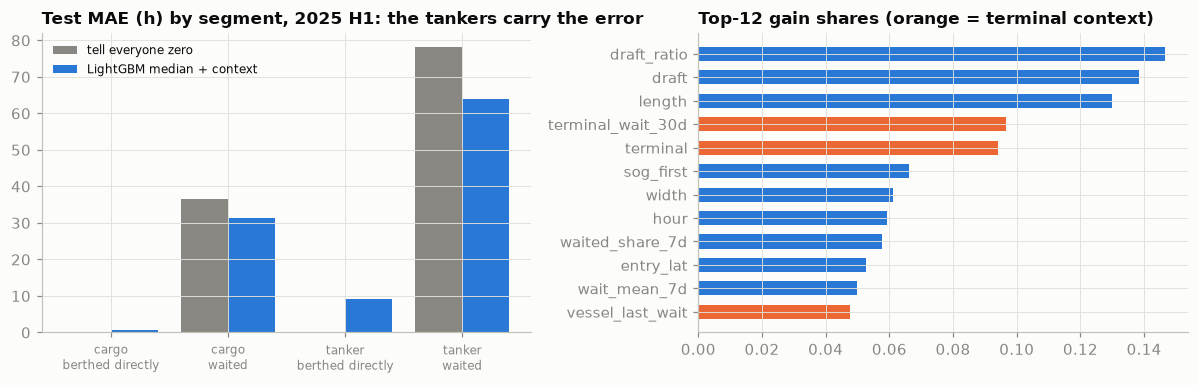

In [11]:
champion = models[("median", "base + terminal context")]
p_te = predict(champion, BASE + KB, te)
seg = pd.DataFrame({"cls": V.cls[te].values, "waited": np.where(y[te].values > 0, "waited", "berthed directly"), "y": y[te].values, "p": p_te})
seg_mae = seg.assign(err_model=lambda d: (d.y - d.p).abs(), err_zero=lambda d: d.y).groupby(["cls", "waited"])[["err_zero", "err_model"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
xs = np.arange(len(seg_mae))
ax.bar(xs - 0.2, seg_mae.err_zero, width=0.4, color=MUTED, label="tell everyone zero")
ax.bar(xs + 0.2, seg_mae.err_model, width=0.4, color=SERIES[0], label="LightGBM median + context")
ax.set_xticks(xs); ax.set_xticklabels([f"{a}\n{b}" for a, b in seg_mae.index], fontsize=8)
ax.set_title("Test MAE (h) by segment, 2025 H1: the tankers carry the error"); ax.legend(fontsize=8)
ax = axes[1]
imp = pd.Series(champion.booster_.feature_importance("gain"), index=BASE + KB).sort_values(ascending=False).head(12)
ax.barh(imp.index[::-1], imp.values[::-1] / imp.sum(), color=[SERIES[1] if f in KB else SERIES[0] for f in imp.index[::-1]], height=0.6)
ax.set_title("Top-12 gain shares (orange = terminal context)")
plt.tight_layout()
display(seg_mae.round(1).rename(columns={"err_zero": "MAE tell zero", "err_model": "MAE model"}).T)
rho = V.loc[tr, ["wait_h"]].join(X.loc[tr, ["queue_all", "queue_tankers", "berths_busy", "terminal_busy", "wait_mean_7d", "draft_ratio"]]).corr("spearman").wait_h.drop("wait_h")
print("Spearman correlation with the wait (training arrivals):", ", ".join(f"{k} {v:+.2f}" for k, v in rho.items()))

The error lives in waiting tankers (63.9 h after the model, 78.1 h for the zero rule). Draft and length carry the model; the queue's Spearman correlation with the wait is −0.05, the draft ratio's +0.28. Waiting here is about the ship and its berth, not the line ahead.

## 5 · The operating point: what to tell the ship

*Part B · Given model · package `promise_cost`; C3 asks you to own the two hourly prices.*

The port tells each arriving ship a wait ŵ. Two errors have two prices, both assumptions:

- the ship waits **longer** than told: anchor time it could have spent slow-steaming, `ANCHOR_COST_USD_PER_H` = $2,000 an hour;
- the ship was told to wait **longer** than needed: berth, gang and pilots idle, `IDLE_BERTH_COST_USD_PER_H` = $1,500 an hour.

With linear costs the cheapest promise is a quantile, q = 2,000 / 3,500 = 0.57 (Gneiting, 2011). We check the formula on data: quantile models at q = 0.3 … 0.9, priced on validation.

,cost per arrival (valid),share told to wait (valid),coverage (valid)
q = 0.3,"$23,444",17.3%,78.1%
q = 0.4,"$23,008",22.5%,79.0%
q = 0.5,"$22,190",30.3%,80.7%
q = 0.6,"$22,226",41.5%,82.3%
q = 0.7,"$23,500",50.2%,85.1%
q = 0.8,"$27,985",60.7%,88.7%
q = 0.9,"$39,834",78.0%,92.2%


tell everyone zero on validation: $25,150 per arrival


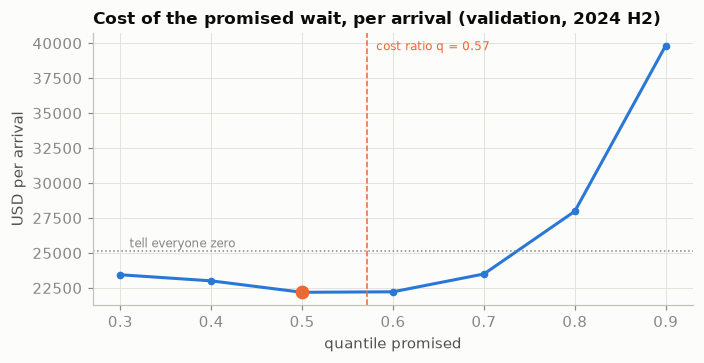

In [12]:
QS = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
cols = BASE + KB
qmodels = {q: fit(cols, "quantile", alpha=q) for q in QS}
def promise_cost(w, promised):                        # USD per arrival
    return (ANCHOR_COST_USD_PER_H * np.clip(w - promised, 0, None) + IDLE_BERTH_COST_USD_PER_H * np.clip(promised - w, 0, None)).mean()
curve = pd.DataFrame({q: {"cost per arrival (valid)": promise_cost(y[va].values, predict(m, cols, va)),
                          "share told to wait (valid)": (predict(m, cols, va) >= 1).mean(),
                          "coverage (valid)": (y[va].values <= predict(m, cols, va) + 1e-9).mean()} for q, m in qmodels.items()}).T
Q_STAR = float(curve["cost per arrival (valid)"].idxmin())
q_theory = ANCHOR_COST_USD_PER_H / (ANCHOR_COST_USD_PER_H + IDLE_BERTH_COST_USD_PER_H)
status_quo_va = promise_cost(y[va].values, 0)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(curve.index, curve["cost per arrival (valid)"], "-o", ms=4, lw=2, color=SERIES[0], label="promise = model quantile q")
ax.axhline(status_quo_va, color=MUTED, ls=":", lw=1); ax.text(0.31, status_quo_va * 1.01, "tell everyone zero", color=MUTED, fontsize=8)
ax.axvline(q_theory, color=SERIES[1], ls="--", lw=1); ax.text(q_theory + 0.01, ax.get_ylim()[1] * 0.97, f"cost ratio q = {q_theory:.2f}", color=SERIES[1], fontsize=8)
ax.plot([Q_STAR], [curve.loc[Q_STAR, "cost per arrival (valid)"]], "o", color=SERIES[1], ms=8)
ax.set_title("Cost of the promised wait, per arrival (validation, 2024 H2)"); ax.set_xlabel("quantile promised"); ax.set_ylabel("USD per arrival")
plt.tight_layout()
display(curve.rename(index=lambda q: f"q = {q:.1f}").style.format({"cost per arrival (valid)": "${:,.0f}", "share told to wait (valid)": "{:.1%}",
                                                                   "coverage (valid)": "{:.1%}"}))
print(f"tell everyone zero on validation: ${status_quo_va:,.0f} per arrival")

The curve is flat between q = 0.5 ($22,190 per arrival) and q = 0.6 ($22,226), with the formula's 0.57 between them: theory and data agree. Telling everyone zero costs $25,150 on the same arrivals; above 0.7 idle berths dominate.

In [13]:
p_q = predict(qmodels[Q_STAR], cols, te)
yt = y[te].values
op = pd.Series({"arrivals (2025 H1)": te.sum(), "told to expect a wait ≥ 1 h": int((p_q >= 1).sum()),
                "of those, actually waited": int(((p_q >= 1) & (yt > 0)).sum()),
                "waits > 24 h told ≥ 12 h": int(((p_q >= 12) & (yt > LONG_WAIT_H)).sum()), "waits > 24 h": int((yt > LONG_WAIT_H).sum()),
                "cost per arrival, model ($)": promise_cost(yt, p_q), "cost per arrival, tell zero ($)": promise_cost(yt, 0),
                "saving over the half-year ($)": (promise_cost(yt, 0) - promise_cost(yt, p_q)) * te.sum()})
print(f"chosen on validation: q = {Q_STAR:.1f} (newsvendor ratio {q_theory:.2f}); applied unchanged to 2025 H1")
display(op.to_frame("2025 H1").style.format("{:,.0f}"))

chosen on validation: q = 0.5 (newsvendor ratio 0.57); applied unchanged to 2025 H1


,2025 H1
arrivals (2025 H1),"1,554"
told to expect a wait ≥ 1 h,480
"of those, actually waited",235
waits > 24 h told ≥ 12 h,94
waits > 24 h,167
"cost per arrival, model ($)","19,922"
"cost per arrival, tell zero ($)","22,315"
saving over the half-year ($),"3,719,643"


Applied unchanged to 2025 H1, the promise tells 480 ships to expect at least an hour, and 235 do wait; 94 of the 167 waits over 24 h get 12 h or more of warning. Under the assumed prices it costs $19,922 per arrival against $22,315 for "come straight in", about $3.7 M less over the half-year, and only as good as the prices (task C3).

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test (`label_stats` compares label versions).*

Four shortcuts, each measured here.

**Trap 1 — the geofence is the label.** "Waiting at anchor" is whatever the geofence, stop length and anchorage list say. The table runs five definitions over the berthed arrivals each one finds (lay-ups included). Dropping the south-east overflow anchorage (v1) lowers the waiting share from 21.3 % to 19.9 % and the mean wait from 15.4 to 13.8 h. Crews' own statuses agree with the learned geofence at this level of aggregation. The published `delay_minutes` calls 99.9 % of arrivals delayed, because it counts the transit.

In [14]:
def label_stats(Vx, obs_only=True):
    b = Vx[Vx.wait_h.notna()]
    if obs_only and "zone_first" in b:
        b = b[b.zone_first == 0]
    w = b.wait_h
    return {"berthed visits": len(b), "waited": (w > 0).mean(), "mean wait (h)": w.mean(), f"> {LONG_WAIT_H} h": (w > LONG_WAIT_H).mean(),
            f"> {MAX_WAIT_H} h": int((w > MAX_WAIT_H).sum())}

versions = {"v2 · learned geofence + overflow (ours)": V}
versions["v1 · learned geofence, bay anchorages only"] = make_visits(anchorages=ANCHORAGES["v1"])[0]
versions["v2 · stops ≥ 2 h"] = make_visits(min_stop_min=120)[0]
versions["crew-typed status (1 → 5)"] = make_visits(use_status=True)[0]
lab = pd.DataFrame({k: label_stats(v) for k, v in versions.items()}).T
# the published label, and models trained on one definition but judged on ours
V = V.join(pub.set_index(["vessel", "pub_visit", "half"])[["pub_delay_h", "pub_waiting_share", "pub_time_in_zone_max"]],
           on=["vessel", "pub_visit", "half"])
lab.loc["published delay_minutes (entry → moored)"] = label_stats(V.assign(wait_h=V.pub_delay_h.where(berthed)))
display(lab.style.format({"berthed visits": "{:,.0f}", "waited": "{:.1%}", "mean wait (h)": "{:.1f}", f"> {LONG_WAIT_H} h": "{:.1%}", f"> {MAX_WAIT_H} h": "{:,.0f}"}))
v1 = versions["v1 · learned geofence, bay anchorages only"].wait_h.reindex(V.index)
ok_pub = tr & V.pub_delay_h.notna()
trap1 = {"trained on ours (v2)": scores(y[te], predict(champion, cols, te)),
         "trained on v1 (bay anchorages only)": scores(y[te], predict(fit(cols, "l1", mask=tr & v1.notna(), target=v1.clip(upper=MAX_WAIT_H)), cols, te)),
         "trained on published delay_minutes": scores(y[te], predict(fit(cols, "l1", mask=ok_pub, target=V.pub_delay_h), cols, te))}
print(f"published label vs ours on the same berthed arrivals: Spearman {V.loc[observed & ~lay_up, ['wait_h', 'pub_delay_h']].corr('spearman').iloc[0, 1]:.2f}; "
      f"median published 'delay' for ships that berthed directly: {V.pub_delay_h[observed & (V.wait_h == 0)].median():.1f} h")
display(pd.DataFrame(trap1).T.iloc[:, :3].style.format("{:.2f}").set_caption("all scored against the v2 label, test 2025 H1"))

,berthed visits,waited,mean wait (h),> 24 h,> 336 h
v2 · learned geofence + overflow (ours),"7,887",21.3%,15.4,13.4%,52
"v1 · learned geofence, bay anchorages only","7,887",19.9%,13.8,12.4%,46
v2 · stops ≥ 2 h,"7,863",20.6%,15.1,13.2%,51
crew-typed status (1 → 5),"8,017",21.0%,15.3,13.4%,53
published delay_minutes (entry → moored),"7,840",99.9%,19.3,15.8%,45


published label vs ours on the same berthed arrivals: Spearman 0.69; median published 'delay' for ships that berthed directly: 3.3 h


,MAE (h),MAE on waits > 24 h,bias (h)
trained on ours (v2),10.51,78.16,-7.20
trained on v1 (bay anchorages only),10.74,82.54,-8.12
trained on published delay_minutes,12.94,71.61,-2.76


A model trained on v1 and judged on v2 scores 82.54 h on long waits against 78.16 h, and one trained on the published label is worse than doing nothing (MAE 12.94 against 11.16 h). The fix is governance: version the label definition, log it with every run, and never compare metrics across versions (C1, C5).

**Trap 2 — AIS gaps make and break visits.** The silence threshold decides what a visit is. Too short (3 h) and coverage holes cut stays in two: 15,310 visits, 939 berthed ones whose arrival we never saw. Too long (96 h) and a ship that leaves and returns becomes one visit whose "wait" includes the trip away: lay-ups rise from 53 to 72 and the mean wait to 16.8 h. The published `visit_id` is the extreme: 6,562 "visits", median 163 h long, mean wait 236.9 h. Between 12 h and 96 h the waiting share barely moves (20.7–21.2 %), so 12 h is defensible; the silence rate is monitored (Section 7).

In [15]:
pub_visit = pq.read_table(PING_CACHE, columns=["pub_visit"]).column(0).to_numpy()
seg_rows = {"published visit_id (as shipped)": make_visits(key=pub_visit)[0]}
del pub_visit
for g in [3, 12, 96]:
    seg_rows[f"new visit after {g} h of silence" + (" (ours)" if g == VISIT_GAP_H else "")] = V if g == VISIT_GAP_H else make_visits(gap_h=g)[0]
trap2 = pd.DataFrame({k: dict(visits=len(v), **{f"{c}": x for c, x in label_stats(v, obs_only=False).items()},
                              **{"arrival not observed": int((v.wait_h.notna() & (v.zone_first != 0)).sum()) if "zone_first" in v else np.nan,
                                 "median visit (h)": ((v.t_end - v.t_arr) / 3600).median()}) for k, v in seg_rows.items()}).T
display(trap2[["visits", "median visit (h)", "berthed visits", "arrival not observed", "waited", "mean wait (h)", f"> {MAX_WAIT_H} h"]]
        .style.format({"visits": "{:,.0f}", "median visit (h)": "{:,.1f}", "berthed visits": "{:,.0f}", "arrival not observed": "{:,.0f}",
                       "waited": "{:.1%}", "mean wait (h)": "{:.1f}", f"> {MAX_WAIT_H} h": "{:,.0f}"}, na_rep="—"))
silent = np.diff(t)[vessel[1:] == vessel[:-1]]
print(f"silences between consecutive pings of one vessel: > 1 h {(silent > 3600).sum():,} · > 12 h {(silent > 12 * 3600).sum():,} · > 3 days {(silent > 3 * 86400).sum():,}")
del silent

,visits,median visit (h),berthed visits,arrival not observed,waited,mean wait (h),> 336 h
published visit_id (as shipped),"6,562",163.4,"4,628",—,29.1%,236.9,186
new visit after 3 h of silence,"15,310",39.2,"8,773",939,19.8%,13.5,41
new visit after 12 h of silence (ours),"12,910",51.1,"8,321",434,20.7%,15.0,53
new visit after 96 h of silence,"10,434",73.0,"7,951",137,21.2%,16.8,72


silences between consecutive pings of one vessel: > 1 h 15,104 · > 12 h 9,534 · > 3 days 7,237


**Trap 3 — features computed from the visit's future.** "Visit features" built the usual way, group by visit and aggregate, read pings after the arrival. Three such columns (the published waiting-area share, the visit's maximum `time_in_zone_hours`, the visit's length) cut the MAE from 10.51 to 7.60 h and the long-wait error from 78.16 to 42.04 h, taking 38 % of the gain. None exists when the ship enters the bay; the as-of rule belongs in a test (C1).

In [16]:
V["visit_hours"] = (V.t_end - V.t_arr) / 3600
LEAKY = ["pub_waiting_share", "pub_time_in_zone_max", "visit_hours"]
for c in LEAKY:
    X[c] = V[c]
m_leak = fit(cols + LEAKY, "l1")
trap3 = pd.DataFrame({"honest (as of arrival)": scores(y[te], p_te),
                      "+ whole-visit aggregates ⚠": scores(y[te], predict(m_leak, cols + LEAKY, te))}).T
display(trap3.iloc[:, :3].style.format("{:.2f}"))
imp_leak = pd.Series(m_leak.booster_.feature_importance("gain"), index=cols + LEAKY)
print(f"share of the leaky model's gain in the three whole-visit columns: {imp_leak[LEAKY].sum() / imp_leak.sum():.0%}")

,MAE (h),MAE on waits > 24 h,bias (h)
honest (as of arrival),10.51,78.16,-7.20
+ whole-visit aggregates ⚠,7.60,42.04,-0.91


share of the leaky model's gain in the three whole-visit columns: 38%


**Trap 4 — the random split.** Shuffle the arrivals of June 2023 – June 2025 and the model claims a 10.7 % gain over the zero rule and a long-wait MAE of 72.50 h; forward in time the gain is 5.8 % and the long-wait MAE 78.16 h. Neighbouring arrivals share congestion episodes and vessels, so a random split tests on episodes the model trained on. Its raw MAE (11.11) is higher only because the shuffled rows include busier months (zero rule 12.45): compare gains on the same rows.

In [17]:
pool = np.flatnonzero((usable & (V.t_arr < sec(TEST_END))).values)
i_tr, i_te = train_test_split(pool, test_size=0.3, random_state=SEED)
m_rand = lgb.LGBMRegressor(**dict(LGB_PARAMS, objective="l1")).fit(X.iloc[i_tr][cols], y.iloc[i_tr])
r_rand = scores(y.iloc[i_te], np.clip(m_rand.predict(X.iloc[i_te][cols]), 0, None))
r_fwd = scores(y[te], p_te)
trap4 = pd.DataFrame({"random 70/30 (Jun 2023 – Jun 2025)": r_rand, "forward: train → 2025 H1": r_fwd,
                      "  · zero rule, random 30 %": scores(y.iloc[i_te], np.zeros(len(i_te))), "  · zero rule, 2025 H1": scores(y[te], np.zeros(te.sum()))}).T
display(trap4.iloc[:, :3].style.format("{:.2f}"))
print(f"gain over the zero rule · random split {1 - r_rand['MAE (h)'] / trap4.iloc[2, 0]:.1%} · forward {1 - r_fwd['MAE (h)'] / trap4.iloc[3, 0]:.1%}")

,MAE (h),MAE on waits > 24 h,bias (h)
random 70/30 (Jun 2023 – Jun 2025),11.11,72.50,-8.99
forward: train → 2025 H1,10.51,78.16,-7.20
"· zero rule, random 30 %",12.45,86.39,-12.45
"· zero rule, 2025 H1",11.16,94.52,-11.16


gain over the zero rule · random split 10.7% · forward 5.8%


# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: arrivals, queue and wait across 2023–2025

*Part C · Productionise · what your monitoring plan must catch; reuse `psi` and `briefing_facts` (C5, S1).*

Freeze the model trained to June 2024 and run it over every later month, on two clocks as in Task 02: **now** (arrivals, vessel mix, ships at anchor, the AIS silence rate) and **days later**, when each ship berths and its wait and error become known. Labels mature within 14 days by definition.

,arrivals/day,tankers,at anchor (noon),waited,mean wait (h),silences > 1 h per 1k pings
half,,,,,,
2023H2 (Jun–Dec 2023),7.9,20%,13.2,22%,14.3,0.61
2024H1,8.2,21%,15.3,21%,12.9,0.60
2024H2,8.7,20%,14.7,22%,12.5,0.77
2025H1,8.6,19%,13.8,19%,11.0,0.68
2025H2,8.3,18%,12.3,19%,10.0,0.90


monthly ranges · arrivals/day 7.4–9.1 · tanker share 15%–24% · mean wait 6.6–19.4 h (lowest 2025-12)


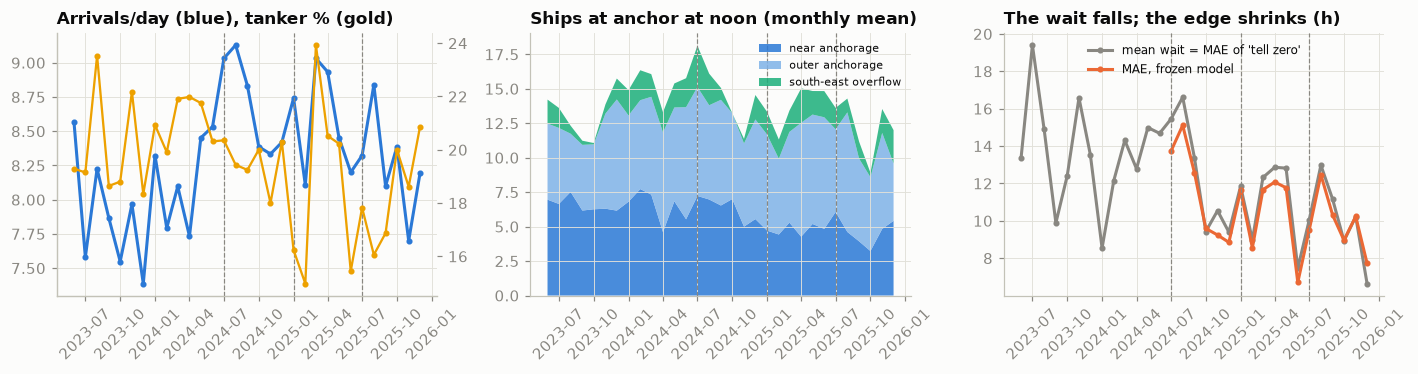

In [18]:
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

U = V[usable].copy()
U["month"] = when(U.t_arr).tz_convert(None).to_period("M")
U["day"] = when(U.t_arr).tz_convert(None).floor("D")
U["pred"] = predict(champion, cols, usable)
days = pd.date_range(WARMUP_END.tz_convert(None).normalize(), "2025-12-31", freq="D") + pd.Timedelta(hours=20)  # 20:00 UTC ≈ noon in LA
noon = np.array([sec(d.tz_localize("UTC")) for d in days])
anchored = pd.DataFrame({ZONES[z]: covering(noon, ANC.t0.values[ANC.zone.values == z], ANC.t1.values[ANC.zone.values == z]) for z in ANCHORAGES["v2"]},
                        index=days.to_period("M"))
daily_arr = U.groupby("day").size().reindex(days.floor("D"), fill_value=0)
ref_daily = daily_arr[daily_arr.index < TRAIN_END.tz_convert(None)].values
mon = U.groupby("month").agg(arrivals=("wait_h", "size"), tanker_share=("cls", lambda c: (c == "tanker").mean()),
                             waited=("wait_h", lambda w: (w > 0).mean()), mean_wait=("wait_h", "mean"),
                             mae_model=("wait_h", lambda w: np.abs(w - U.loc[w.index, "pred"]).mean()), mae_zero=("wait_h", "mean"))
mon = mon.join(anchored.groupby(level=0).mean().sum(axis=1).rename("at_anchor_noon"))
mon["arrivals_per_day"] = mon.arrivals / pd.Series(1, index=days).groupby(days.to_period("M")).size()
month_bounds = np.array([sec(p.to_timestamp().tz_localize("UTC")) for p in mon.index] + [sec(pd.Timestamp("2026-01-01", tz="UTC"))])
same = vessel[1:] == vessel[:-1]
m_code = np.searchsorted(month_bounds, t[1:][same], side="right") - 1
silences = np.bincount(m_code[np.diff(t)[same] > 3600], minlength=len(mon))[:len(mon)]
mon["silences_per_1k_pings"] = 1000 * silences / np.bincount(m_code, minlength=len(mon))[:len(mon)]
del same, m_code
mon.loc[mon.index < TRAIN_END.tz_convert(None).to_period("M"), ["mae_model"]] = np.nan     # in-sample months are not evaluation

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
x_ = mon.index.to_timestamp()
cuts = [TRAIN_END, VALID_END, TEST_END]
ax = axes[0]
ax.plot(x_, mon.arrivals_per_day, "-o", ms=3, lw=2, color=SERIES[0], label="berthed arrivals per day")
ax2 = ax.twinx(); ax2.plot(x_, mon.tanker_share * 100, "-o", ms=3, lw=1.5, color=SERIES[3], label="tanker share (%)"); ax2.grid(False)
ax.set_title("Arrivals/day (blue), tanker % (gold)"); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
ms = anchored.groupby(level=0).mean(); ms.index = ms.index.to_timestamp()
ax.stackplot(ms.index, ms.T.values, colors=[SERIES[0], "#7fb2e8", SERIES[2]], labels=ms.columns, alpha=0.85)
ax.set_title("Ships at anchor at noon (monthly mean)"); ax.legend(fontsize=7, loc="upper right"); ax.tick_params(axis="x", rotation=45)
ax = axes[2]
ax.plot(x_, mon.mae_zero, "-o", ms=3, lw=2, color=MUTED, label="mean wait = MAE of 'tell zero'")
ax.plot(x_, mon.mae_model, "-o", ms=3, lw=2, color=SERIES[1], label="MAE, frozen model")
ax.set_title("The wait falls; the edge shrinks (h)"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
for a in axes:
    for c in cuts:
        a.axvline(c.tz_convert(None), color=MUTED, ls="--", lw=0.8)
plt.tight_layout()
hy = mon.assign(half=[FILES[int(np.searchsorted(bounds, sec(p.to_timestamp().tz_localize("UTC")), side="right"))] for p in mon.index])
hy = hy.groupby("half", sort=False).agg(arrivals_per_day=("arrivals_per_day", "mean"), tanker_share=("tanker_share", "mean"),
                                        at_anchor_noon=("at_anchor_noon", "mean"), waited=("waited", "mean"), mean_wait=("mean_wait", "mean"),
                                        silences_per_1k_pings=("silences_per_1k_pings", "mean"))
display(hy.rename(columns={"arrivals_per_day": "arrivals/day", "tanker_share": "tankers", "at_anchor_noon": "at anchor (noon)",
                            "mean_wait": "mean wait (h)", "silences_per_1k_pings": "silences > 1 h per 1k pings"}).style
        .format({"arrivals/day": "{:.1f}", "tankers": "{:.0%}", "at anchor (noon)": "{:.1f}", "waited": "{:.0%}", "mean wait (h)": "{:.1f}",
                 "silences > 1 h per 1k pings": "{:.2f}"}))
print(f"monthly ranges · arrivals/day {mon.arrivals_per_day.min():.1f}–{mon.arrivals_per_day.max():.1f} · tanker share {mon.tanker_share.min():.0%}–{mon.tanker_share.max():.0%} · "
      f"mean wait {mon.mean_wait.min():.1f}–{mon.mean_wait.max():.1f} h (lowest {mon.mean_wait.idxmin()})")

Volume did not drift: monthly arrivals stay between 7.4 and 9.1 a day (but AIS counts ships, not boxes; task E4). The wait did drift: the half-yearly mean fell from 14.3 h (2023 H2) to 10.0 h (2025 H2), December 2025 was the lowest month at 6.6 h, and ships at anchor at noon fell from 15.3 (2024 H1) to 12.3. That is concept drift under stable inputs, invisible to an input-PSI monitor. The AIS silence rate rose from 0.60 per 1,000 pings (2024 H1) to 0.90 (2025 H2): data-quality drift feeding Trap 2.

In [19]:
# The frozen holdout, read once: the CI gate, and what the drift did to the champion
candidate = fit(cols, "l1", mask=usable & (V.t_arr < sec(TEST_END)))       # retrained on everything before the holdout
rows = {}
for name, msk, mdl in [("validation 2024 H2", va, champion), ("test 2025 H1", te, champion), ("holdout 2025 H2 · frozen champion", ho, champion),
                       ("holdout 2025 H2 · candidate retrained to Jun 2025", ho, candidate)]:
    r = scores(y[msk], predict(mdl, cols, msk)); z = scores(y[msk], np.zeros(msk.sum()))
    rows[name] = {"arrivals": msk.sum(), "mean wait (h)": y[msk].mean(), "MAE model": r["MAE (h)"], "MAE zero rule": z["MAE (h)"],
                  "ratio": r["MAE (h)"] / z["MAE (h)"], f"MAE > {LONG_WAIT_H} h": r[f"MAE on waits > {LONG_WAIT_H} h"],
                  "PSI arrivals/day": psi(ref_daily, daily_arr[(daily_arr.index >= when(V.t_arr[msk].min()).tz_convert(None).floor('D'))
                                                              & (daily_arr.index <= when(V.t_arr[msk].max()).tz_convert(None))].values)}
gate = pd.DataFrame(rows).T
display(gate.style.format({"arrivals": "{:,.0f}", "mean wait (h)": "{:.1f}", "MAE model": "{:.2f}", "MAE zero rule": "{:.2f}", "ratio": "{:.3f}",
                           f"MAE > {LONG_WAIT_H} h": "{:.1f}", "PSI arrivals/day": "{:.2f}"}))
for k in gate.index[2:]:
    print(f"CI gate (holdout MAE ≤ {GATE_MAE_VS_ZERO:.0%} of the zero rule) · {k.split('· ')[1]}: {'PASS' if gate.loc[k, 'ratio'] <= GATE_MAE_VS_ZERO else 'FAIL'}")

,arrivals,mean wait (h),MAE model,MAE zero rule,ratio,MAE > 24 h,PSI arrivals/day
validation 2024 H2,"1,599",12.6,11.61,12.58,0.923,70.9,0.07
test 2025 H1,"1,554",11.2,10.51,11.16,0.942,78.2,0.10
holdout 2025 H2 · frozen champion,"1,520",10.0,9.89,10.01,0.987,66.6,0.03
holdout 2025 H2 · candidate retrained to Jun 2025,"1,520",10.0,9.60,10.01,0.959,67.3,0.03


CI gate (holdout MAE ≤ 97% of the zero rule) · frozen champion: FAIL
CI gate (holdout MAE ≤ 97% of the zero rule) · candidate retrained to Jun 2025: PASS


Inputs barely move (PSI of daily arrivals ≤ 0.10), yet the gate refuses the frozen model: its holdout MAE is 0.987 of the zero rule's, above the 0.97 placeholder. A candidate retrained to June 2025 passes at 0.959. The model did not break; the port got quieter, which favours the zero rule over a model that has not seen the change. Hence the policy: retrain monthly once labels mature, and alert when the rolling 30-day MAE ratio crosses the gate. Both sit within two points of it, so task C4 adds a bootstrap interval.

**Where congestion is building.** Stretch S1 asks an LLM to write the harbour master's queue briefing; the context is the work. The cell below assembles it deterministically, pseudonymised and stamped with the geofence version.

In [20]:
# The context a harbour-master briefing would be grounded on (Stretch S1 writes the briefing; no LLM here)
def briefing_facts(at: pd.Timestamp) -> dict:
    now = sec(at)
    cover = (ANC.t0.values <= now) & (ANC.t1.values >= now)
    waiting = ANC[cover].merge(RUNS[(RUNS.state == 2) & (RUNS.t0 <= now)].groupby("visit").t0.min().rename("since"), left_on="visit", right_index=True)
    last30 = noon[(noon < now) & (noon >= now - 30 * 86400)]
    recent = V[(V.t_arr >= now - 12 * 3600) & (V.t_arr < now) & observed]     # callers (the port knows them; here: they later berthed)
    return {"as_of_utc": at.strftime("%Y-%m-%d %H:%M"), "geofence_version": GEOFENCE_VERSION,
            "at_anchor_now": {ZONES[z]: int((waiting.zone == z).sum()) for z in ANCHORAGES["v2"]} | {"total": len(waiting)},
            "at_anchor_30d_mean": round(float(np.mean(covering(last30, ANC.t0.values, ANC.t1.values))), 1),
            "berthings_last_24h": int(in_window(np.array([now]), V.t_berth.dropna().values, 86400)[0]),
            "long_stays_over_14d (likely lay-up, not queue)": int(((now - waiting.since) > MAX_WAIT_H * 3600).sum()),
            "longest_waiting": [{"vessel": f"V{int(V.vessel[r.visit])}", "class": V.cls[r.visit], "hours_so_far": round((now - r.since) / 3600)}
                                for r in waiting[(now - waiting.since) <= MAX_WAIT_H * 3600].sort_values("since").head(3).itertuples()],
            "arrivals_last_12h": [{"vessel": f"V{int(r.vessel)}", "class": r.cls, "predicted_wait_h": round(float(p), 1)}
                                  for r, p in zip(recent.itertuples(), predict(champion, cols, V.index.isin(recent.index)))]}

print(json.dumps(briefing_facts(pd.Timestamp("2025-12-15 16:00", tz="UTC")), indent=1, ensure_ascii=False))

{
 "as_of_utc": "2025-12-15 16:00",
 "geofence_version": "v2",
 "at_anchor_now": {
  "near anchorage": 5,
  "outer anchorage": 1,
  "south-east overflow": 4,
  "total": 10
 },
 "at_anchor_30d_mean": 15.3,
 "berthings_last_24h": 7,
 "long_stays_over_14d (likely lay-up, not queue)": 4,
 "longest_waiting": [
  {
   "vessel": "V1801",
   "class": "tanker",
   "hours_so_far": 271
  },
  {
   "vessel": "V2988",
   "class": "cargo",
   "hours_so_far": 260
  },
  {
   "vessel": "V2630",
   "class": "tanker",
   "hours_so_far": 105
  }
 ],
 "arrivals_last_12h": [
  {
   "vessel": "V101",
   "class": "cargo",
   "predicted_wait_h": 0.0
  },
  {
   "vessel": "V1729",
   "class": "cargo",
   "predicted_wait_h": 0.1
  },
  {
   "vessel": "V1878",
   "class": "tanker",
   "predicted_wait_h": 23.9
  },
  {
   "vessel": "V2925",
   "class": "tanker",
   "predicted_wait_h": 3.3
  }
 ]
}


## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

On 15 December 2025 the facts show 10 ships at anchor against a 30-day mean of 15.3, and 4 of them are long stays over 14 days, not a queue: a briefing that counted them would cry wolf. The label is a definition and the queue a modelling choice; both must be versioned, monitored and explained. The spine, updated with what this notebook found:

| Spine | In this project (updated) |
|---|---|
| Package and container (S02–S03) | `src/port_wait/` (visits, features, train, serve); `POST /eta` per arriving ship returns the promised wait and geofence version |
| Monitoring (S04) | Now: arrivals per day (PSI ≤ 0.10), tanker share (15–24 % by month), ships at anchor, AIS silences per 1,000 pings (0.60 → 0.90), latency. Within 14 days: MAE ratio to the zero rule, rolling 30 days |
| CI/CD gate (S05) | Frozen, fingerprinted 2025 H2; MAE ≤ 0.97 × zero rule (placeholder): frozen model 0.987 fails, retrained 0.959 passes |
| MLflow tracking and registry (S06) | Geofence version, stop and silence thresholds, lay-up cap, windows, features, q = 0.5; `champion`/`challenger` aliases; model card |
| Offline / online training and serving | Online at arrival; monthly retraining once waits mature; the briefing as a batch job |
| Data and model drift | Concept drift: mean wait 14.3 → 10.0 h per half-year under stable arrivals; vessel mix; silence rate |
| Knowledge base and context (S07–S09) | 55,881 triples; SHACL flags the 52 lay-ups; vessel–terminal graph. With terminal context, AUPRC (waits > 24 h) 0.485 → 0.519, MAE 10.54 → 10.51 h |
| GenAI and context engineering (S10–S11) | Harbour-master briefing grounded only in `briefing_facts()`, with a golden set from those facts; the same pattern fits Malta Freeport |
| Governance | AIS is public, but tracks identify operators: MMSI pseudonymised, names never read; CC BY 4.0; AI Act position as your reading (E2) |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Version the geofence and label definition; test that no feature reads a ping after `t_arr` and that a synthetic track with a 6-hour hole segments correctly. Replace the terminal stand-in with the zone of the ship's previous call and report how much context gain survives.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary the two hourly prices, show how the quantile and the 2025 H1 saving move, and write the ADR recording the prices and who signed them off.
- **C4 — Package and gate.** Move the pipeline into `src/port_wait/` with tests, containerise the `POST /eta` service, and gate CI on MAE against a frozen, fingerprinted 2025 H2 with a bootstrap interval (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs with the geofence version, the champion under an alias, a model card, and a monitoring plan with Section 7's signals and the retraining trigger the gate implies (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation, properly.** Name the berth zones from the ports' terminal maps, add terminal type to the ontology and its shapes, and re-run the ablation with and without terminal context (Sessions 07–09).
- **E2 — Governance of public tracks.** When can AIS become personal data? Add the CC BY attribution, your reading of the EU AI Act, what a published forecast reveals about competitors, and what running this at Malta Freeport would need, from whom.
- **E3 — Error parity across ships.** Measure cost per arrival and long-wait recall by class, length and berth zone on 2025 H1; write the two sentences a terminal customer would read.
- **E4 — Volumes the pings cannot see.** Join the ports' monthly TEU statistics to Section 7: does volume explain the 2025 fall in waiting?

### Stretch

- **S1 — The harbour-master briefing.** An LLM writes it grounded only in `briefing_facts()`; a golden set of 30 timestamps checks every number; test a planted prompt injection; log prompt versions and cost per briefing (Sessions 10–11).
- **S2 — Streaming arrival scoring.** Keep the queue state in a streaming job, score arrivals within a latency budget, and cost it against an hourly batch (Session 11).
- **S3 — Promise earlier.** The box sees a ship about three hours before a direct berthing; just-in-time arrival needs a day. Specify, as an ADR, the data a 24-hour promise would need (wider-area AIS, berth schedule, declared ETAs), who owns it, and the data contracts.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; MMSI pseudonymised, names never read
- [ ] `README.md` states the window, splits, label version and data source (Kaggle, CC BY 4.0, attribution)
- [ ] Visits rebuilt from pings; label versioned; as-of test in the suite; traps removed
- [ ] Operating point from the two prices, with the ADR
- [ ] CI with the holdout gate; registered model, model card, monitoring plan
- [ ] Knowledge base with SHACL and the ablation; a one-page recommendation for the harbour master
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `duckdb`, `scikit-learn`, `lightgbm`, `networkx`, `rdflib`, `pyshacl`, `kagglehub` (pinned in `requirements.txt`).
- Nguyen, K. (2026). *LA/LB Maritime Trajectory & AIS Dataset 2023–2025*, Kaggle, CC BY 4.0; pings from NOAA Marine Cadastre AIS.
- ITU-R Recommendation M.1371-5 (2014): AIS technical characteristics, including navigational status and ship-type codes.
- Gneiting, T. (2011). *Quantiles as optimal point forecasts.* International Journal of Forecasting 27(2).
- Kaufman, S., Rosset, S., Perlich, C. (2012). *Leakage in Data Mining: Formulation, Detection, and Avoidance.* ACM TKDD.
- W3C (2017). *Shapes Constraint Language (SHACL).*

In [21]:
print(f"pandas {pd.__version__} · pyarrow {pa.__version__} · duckdb {duckdb.__version__} · lightgbm {lgb.__version__} · "
      f"scikit-learn {__import__('sklearn').__version__} · networkx {nx.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time() - T_START:.0f}s")

pandas 3.1.0 · pyarrow 26.0.0 · duckdb 2.0.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · networkx 3.7 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 76s
